In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

In [2]:
DATA_DIR = r'E:\Claude\euclid-analysis\output\initial_analysis'

df_complexity = pd.read_csv(f'{DATA_DIR}/human_proof_complexity.csv', dtype={'Proposition': str})
df_expert_cls = pd.read_csv(f'{DATA_DIR}/expert_verified_classification.csv', dtype={'Proposition': str})
df_final_cls  = pd.read_csv(f'{DATA_DIR}/final_classification.csv', dtype={'Proposition': str})

In [3]:
df_expert_cls

,Proposition,Book,Prop_Num,RunA,RunB,RunC
0,1.1,1,1,G,G,G
1,1.2,1,2,G,G,G
2,1.3,1,3,P,P,P
3,1.4,1,4,G,G,G
4,1.5,1,5,G,G,G
...,...,...,...,...,...,...
460,13.14,13,14,D,G,D
461,13.15,13,15,G,G,D
462,13.16,13,16,G,E,E
463,13.17,13,17,D,E,D


In [4]:
df_complexity

,Proposition,Book,Prop_Num,Word_Count,Reference_Count,Available_Tools
0,1.1,1,1,188,4,14
1,1.2,1,2,226,6,15
2,1.3,1,3,138,4,16
3,1.4,1,4,293,1,17
4,1.5,1,5,360,4,18
...,...,...,...,...,...,...
460,13.14,13,14,607,4,520
461,13.15,13,15,513,2,521
462,13.16,13,16,1376,10,522
463,13.17,13,17,1469,12,523


In [5]:
rows_expert = []
for _, r in df_expert_cls.iterrows():
    prop = r['Proposition']
    cx = df_complexity[df_complexity['Proposition'] == prop]
    if cx.empty:
        continue
    cx = cx.iloc[0]
    for run in ['RunA', 'RunB', 'RunC']:
        rows_expert.append({
            'prop': prop,
            'book': int(cx['Book']),
            'cat': r[run],
            'word_count': int(cx['Word_Count']),
            'ref_count': int(cx['Reference_Count']),
            'avail_tools': int(cx['Available_Tools']),
        })
df_expert = pd.DataFrame(rows_expert)

In [6]:
df_expert

,prop,book,cat,word_count,ref_count,avail_tools
0,1.1,1,G,188,4,14
1,1.1,1,G,188,4,14
2,1.1,1,G,188,4,14
3,1.2,1,G,226,6,15
4,1.2,1,G,226,6,15
...,...,...,...,...,...,...
1390,13.17,13,E,1469,12,523
1391,13.17,13,D,1469,12,523
1392,13.18,13,D,1328,12,524
1393,13.18,13,D,1328,12,524


In [7]:
rows_final = []
for _, r in df_final_cls.iterrows():
    prop = r['Proposition']
    cx = df_complexity[df_complexity['Proposition'] == prop]
    if cx.empty:
        continue
    cx = cx.iloc[0]
    for run in ['RunA', 'RunB', 'RunC']:
        rows_final.append({
            'prop': prop,
            'book': int(cx['Book']),
            'cat': r[run],
            'word_count': int(cx['Word_Count']),
            'ref_count': int(cx['Reference_Count']),
            'avail_tools': int(cx['Available_Tools']),
        })
df_final = pd.DataFrame(rows_final)

In [8]:
df_final

,prop,book,cat,word_count,ref_count,avail_tools
0,1.1,1,G,188,4,14
1,1.1,1,G,188,4,14
2,1.1,1,G,188,4,14
3,1.2,1,G,226,6,15
4,1.2,1,G,226,6,15
...,...,...,...,...,...,...
1390,13.17,13,D,1469,12,523
1391,13.17,13,D,1469,12,523
1392,13.18,13,D,1328,12,524
1393,13.18,13,D,1328,12,524


In [9]:
print(f"Expert-verified: {df_expert['cat'].value_counts().sort_index().to_dict()}")
print(f"Final:           {df_final['cat'].value_counts().sort_index().to_dict()}")

Expert-verified: {'D': 371, 'E': 26, 'G': 934, 'P': 64}
Final:           {'D': 379, 'G': 952, 'P': 64}


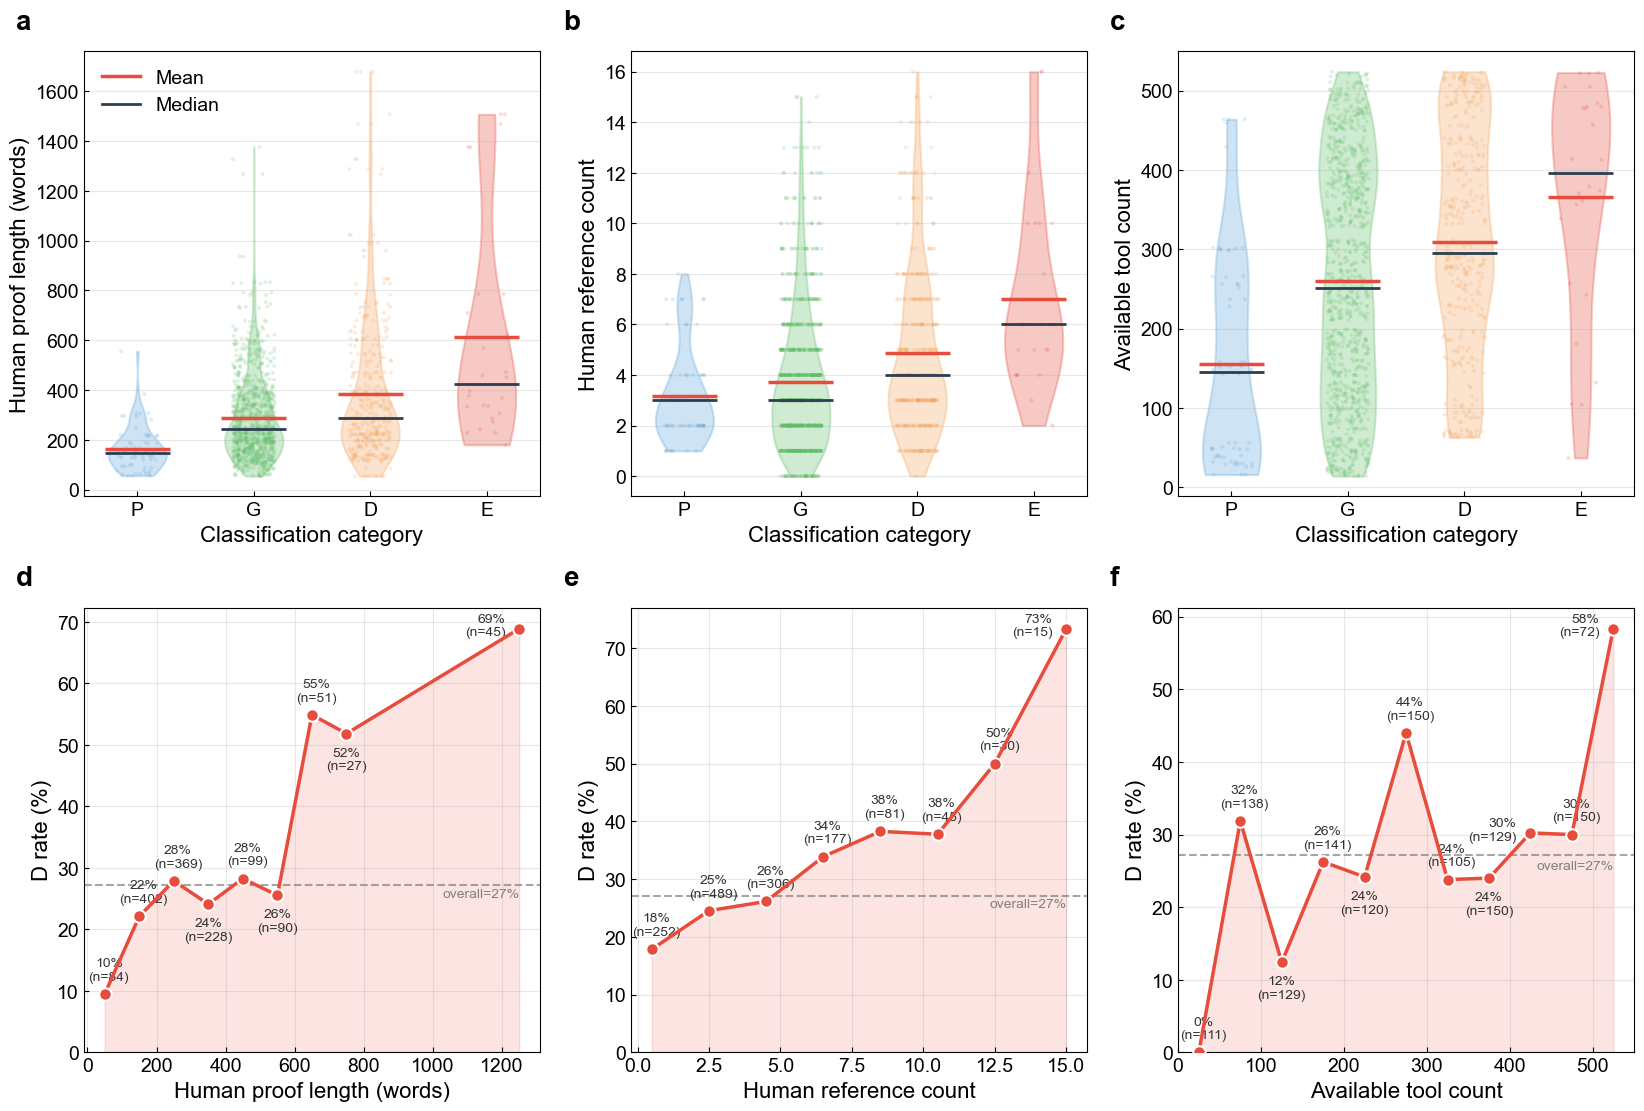

In [11]:
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['font.family'] = 'Arial'

cats_row1 = [c for c in ['P', 'G', 'D', 'E'] if c in df_expert['cat'].values]
cat_full = {'P': 'Perfect', 'G': 'Granularity', 'D': 'Path diff', 'E': 'Error'}
cat_colors = {'P': '#5da5da', 'G': '#60bd68', 'D': '#f5a45d', 'E': '#e74c3c'}

rng = np.random.default_rng(42)

fig, axes = plt.subplots(2, 3, figsize=(20, 13))

# ====== Row 1: 小提琴图 (专家验证, 4类) ======
vars_row1 = [
    ('word_count', 'Human proof length (words)'),
    ('ref_count', 'Human reference count'),
    ('avail_tools', 'Available tool count'),
]

for col_idx, (var, ylabel) in enumerate(vars_row1):
    ax = axes[0, col_idx]
    data_by_cat = [df_expert[df_expert['cat'] == cat][var].values for cat in cats_row1]
    positions = list(range(len(cats_row1)))

    parts = ax.violinplot(data_by_cat, positions=positions,
                          showmeans=False, showmedians=False, showextrema=False)
    for i, pc in enumerate(parts['bodies']):
        pc.set_facecolor(cat_colors[cats_row1[i]])
        pc.set_alpha(0.3)
        pc.set_edgecolor(cat_colors[cats_row1[i]])
        pc.set_linewidth(1.5)

    for i, cat in enumerate(cats_row1):
        vals = df_expert[df_expert['cat'] == cat][var].values
        jitter = rng.uniform(-0.18, 0.18, len(vals))
        ax.scatter(np.full(len(vals), i) + jitter, vals,
                   c=cat_colors[cat], alpha=0.2, s=8, edgecolors='none', zorder=2)

    for i, cat in enumerate(cats_row1):
        vals = df_expert[df_expert['cat'] == cat][var].values
        ax.hlines(np.mean(vals), i - 0.28, i + 0.28, colors='#e74c3c', lw=2.5, zorder=4)
        ax.hlines(np.median(vals), i - 0.28, i + 0.28, colors='#2c3e50', lw=2, zorder=4)

    #xlabels = [f'{c}\n(n={len(df_expert[df_expert["cat"] == c])})' for c in cats_row1]
    xlabels = [f'{c}' for c in cats_row1]
    ax.set_xticks(positions)
    ax.set_xticklabels(xlabels, fontsize=14)
    ax.set_ylabel(ylabel, fontsize=16)
    ax.tick_params(axis='y', labelsize=14)
    ax.set_xlabel('Classification category', fontsize=16)
    #ax.set_title(f'({chr(97 + col_idx)}) {ylabel}', fontsize=12, fontweight='bold')
    ax.grid(alpha=0.3, axis='y')

    if col_idx == 0:
        legend_el = [
            Line2D([0], [0], color='#e74c3c', lw=2.5, label='Mean'),
            Line2D([0], [0], color='#2c3e50', lw=2, label='Median'),
        ]
        ax.legend(handles=legend_el, fontsize=14, loc='upper left', frameon=False)

# ====== Row 2: D率折线图 (最终分类) ======
overall_d_rate = len(df_final[df_final['cat'] == 'D']) / len(df_final) * 100

def plot_d_rate(ax, var, bins, xlabel, panel_letter, show_books=False, min_n=15, custom_offsets=None):
    df_tmp = df_final.copy()
    df_tmp['_bin'] = pd.cut(df_tmp[var], bins=bins)

    pts = []
    for b in sorted(df_tmp['_bin'].dropna().unique()):
        sub = df_tmp[df_tmp['_bin'] == b]
        if len(sub) < min_n:
            continue
        mid = (b.left + b.right) / 2
        d_rate = len(sub[sub['cat'] == 'D']) / len(sub) * 100
        n = len(sub)

        if show_books:
            bks = sorted(sub['book'].unique())
            bk_str = f'Bk{bks[0]}' if len(bks) == 1 else f'Bk{bks[0]}-{bks[-1]}'
            label = f'{d_rate:.0f}%\n({bk_str}, n={n})'
        else:
            label = f'{d_rate:.0f}%\n(n={n})'
        pts.append({'mid': mid, 'd_rate': d_rate, 'n': n, 'label': label})

    pts = pd.DataFrame(pts)

    ax.fill_between(pts['mid'], 0, pts['d_rate'], alpha=0.15, color='#e74c3c')
    ax.plot(pts['mid'], pts['d_rate'], 'o-', color='#e74c3c', lw=2.5, markersize=9,
            markerfacecolor='#e74c3c', markeredgecolor='white', markeredgewidth=1.5, zorder=5)

    for i, row in pts.iterrows():
        # 默认：点上方
        xytext = (3, 10)
        ha = 'center'
        if custom_offsets and (i + 1) in custom_offsets:
            direction = custom_offsets[i + 1]
            if direction == 'below':
                xytext = (0, -26)
            elif direction == 'left':
                xytext = (-10, -5)
                ha = 'right'
        ax.annotate(row['label'], (row['mid'], row['d_rate']),
                    textcoords='offset points', xytext=xytext,
                    ha=ha, fontsize=10, color='#333333')

    ax.axhline(overall_d_rate, color='gray', ls='--', lw=1.5, alpha=0.7)
    ax.text(pts['mid'].iloc[-1], overall_d_rate - 2,
            f'overall={overall_d_rate:.0f}%', ha='right', fontsize=10, color='gray')

    ax.set_xlabel(xlabel, fontsize=16)
    ax.set_ylabel('D rate (%)', fontsize=16)
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)
    #ax.set_title(f'({panel_letter}) D Rate by {xlabel}', fontsize=12, fontweight='bold')
    ax.grid(alpha=0.3)
    ax.set_ylim(bottom=0)

# (d) D率 vs 单词数
wc_bins = [0, 100, 200, 300, 400, 500, 600, 700, 800, 1700]
plot_d_rate(axes[1, 0], 'word_count', wc_bins, 'Human proof length (words)', 'd',
            custom_offsets={4: 'below', 6: 'below', 8: 'below', 9: 'left'})

# (e) D率 vs 引用数
rc_bins = [-0.5, 1.5, 3.5, 5.5, 7.5, 9.5, 11.5, 13.5, 16.5]
plot_d_rate(axes[1, 1], 'ref_count', rc_bins, 'Human reference count', 'e',
            custom_offsets={8: 'left'})

# (f) D率 vs 可用工具数
at_max = int(df_final['avail_tools'].max()) + 50
at_bins = list(range(0, at_max + 1, 50))
plot_d_rate(axes[1, 2], 'avail_tools', at_bins, 'Available tool count', 'f', show_books=False,
            custom_offsets={3: 'below', 5: 'below', 8: 'below', 9: 'left', 11: 'left'})

for i in range(2):
    for j in range(3):
        axes[i, j].text(-0.15, 1.05, chr(97 + i * 3 + j),
                        transform=axes[i, j].transAxes,
                        fontsize=20, fontweight='bold')

#fig.suptitle('Classification Category vs Proof Difficulty Indicators',fontsize=15, fontweight='bold', y=1.01)
plt.subplots_adjust(hspace=0.25, wspace=0.2)
#plt.savefig('E:/AI证明与人类证明的差异/Opus4.6正式实验/分析结果/figure2.pdf', dpi=300, bbox_inches='tight')
plt.show()